# `Perceptron e Adaline -  Efeito da ordem dos exemplos`

##*Pergunta principal: Os algoritmos chegam sempre à mesma solução?*

### `Dupla:`

Anysabele de Paula Barbosa Santos

Millena Ferreira Marçal das Neves

## `Protocolo desta dupla`

- **Conjunto de dados:** exatamente o mesmo conjunto linearmente separável da dupla 1, sintético, com 2 atributos e 2 classes, sem sobreposição. Os atributos são padronizados antes do treinamento dos modelos.

- **Variável experimental:** **ordem de apresentação dos exemplos**. No cenário de ordem fixa, os exemplos são apresentados sempre na mesma sequência. No cenário embaralhado, a ordem dos exemplos é reembaralhada a cada época. Cada execução utiliza uma semente aleatória diferente para controlar o embaralhamento.

- **Critério de parada:** **número de épocas**, utilizando um orçamento fixo de épocas para todas as execuções.

- **Repetições:** o experimento é repetido com **5 sementes aleatórias**, permitindo analisar a variabilidade dos resultados entre diferentes ordens de apresentação.

- **Resultados analisados:** pesos e bias finais, número de épocas, acurácia de treinamento e teste, erro durante o treinamento, matrizes de confusão e fronteiras de decisão.

## `Roteiro do notebook`

1. Geração dos dados
2. Divisão treino/teste e padronização
3. Implementação do Perceptron
4. Implementação do Adaline
5. Desenho experimental do efeito da ordem
6. Resultados por semente
7. Média e desvio-padrão
8. Evolução do erro durante o treinamento
9. Fronteiras de decisão encontradas
10. Matrizes de confusão
11. Boxplots e análise da variabilidade
12. Discussão: relacionando os resultados às regras de aprendizagem
13. Conclusão

### `Importação das bibliotecas`

In [ ]:
import numpy as np #bib para gerar numeros aleátorios
import matplotlib.pyplot as plt #bib para graficos

### `Geração dos dados`

Seguimos exatamente a especificação definida para a dupla 1 (da qual a Dupla 6 reaproveita o conjunto de dados):

- Dados **sintéticos**, com 2 atributos e 2 classes;
- Gerados aleatoriamente a partir de **distribuições uniformes em regiões disjuntas**, o que garante (por construção, não apenas "na prática") que **não há sobreposição** entre as classes:
  - Classe **0**: `uniform(low=[-3.0, -3.0], high=[-0.5, -0.5])`
  - Classe **1**: `uniform(low=[0.5, 0.5], high=[3.0, 3.0])`
- **200 pontos por classe** (400 no total).

In [ ]:
n_amostras = 400
n_classes = n_amostras//2
seed_dados = 42
test_size = 0.3

In [ ]:
#gerador de numeros aleatorios
rgn = np.random.default_rng(seed_dados)

In [ ]:
# classe 0 (exemplo: região inferior esquerda)
x_class_0 = rgn.uniform(low=[-3.0, -3.0],
                        high=[-0.5, -0.5],
                        size=(n_classes, 2))

# classe 1 (exemplo: região superior direita)
x_class_1 = rgn.uniform(low=[0.5, 0.5],
                        high=[3.0, 3.0],
                        size=(n_classes, 2))

In [ ]:
#rotulos para classes
y_class_0 = np.zeros(n_classes)
y_class_1 = np.ones(n_classes)

In [ ]:
#uniao das duas clases
x = np.vstack((x_class_0,x_class_1)) #as classes estao empilhadas > 100 classe 0 e 100 da classe 1
y = np.concatenate((y_class_0,y_class_1))

In [ ]:
#embaralhamento
indices = rgn.permutation(n_amostras)
x = x[indices]
y = y[indices]


### `Divisão treino/teste e padronização`

In [ ]:
n_test = int(test_size*n_amostras)

x_train = x[:-n_test]
y_train = y[:-n_test]

x_test = x[-n_test:]
y_test = y[-n_test:]

In [ ]:
# a média e o desvio padrão são calculados só no conjunto de treino
mean_train = np.mean(x_train, axis=0)
std_train = np.std(x_train, axis=0)

x_train_pad = (x_train - mean_train) / std_train
x_test_pad = (x_test - mean_train) / std_train

In [ ]:
#sementes para o treinamento // usado para controlar a ordem dos exemplos durante o treinamento
seed_treinamento = [10, 20, 30, 40, 50]
for seed_treino in seed_treinamento:
    rng_treino = np.random.default_rng(seed_treino)


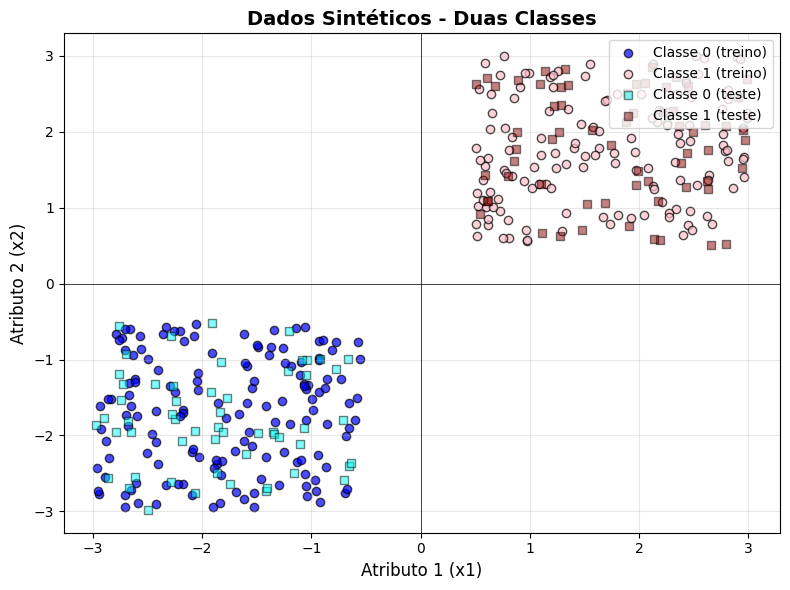

In [ ]:
# @title
##plot dos dados
fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(x_train[y_train == 0, 0], x_train[y_train == 0, 1],
           color='blue', alpha=0.7, label='Classe 0 (treino)', edgecolors='k')
ax.scatter(x_train[y_train == 1, 0], x_train[y_train == 1, 1],
           color='pink', alpha=0.7, label='Classe 1 (treino)', edgecolors='k')
ax.scatter(x_test[y_test == 0, 0], x_test[y_test == 0, 1],
           color='cyan', alpha=0.5, label='Classe 0 (teste)', marker='s', edgecolors='k')
ax.scatter(x_test[y_test == 1, 0], x_test[y_test == 1, 1],
           color='darkred', alpha=0.5, label='Classe 1 (teste)', marker='s', edgecolors='k')

ax.set_title('Dados Sintéticos - Duas Classes', fontsize=14, fontweight='bold')
ax.set_xlabel('Atributo 1 (x1)', fontsize=12)
ax.set_ylabel('Atributo 2 (x2)', fontsize=12)
ax.legend(loc='upper right')
ax.grid(True, alpha=0.3)
ax.axhline(y=0, color='black', linestyle='-', linewidth=0.5)
ax.axvline(x=0, color='black', linestyle='-', linewidth=0.5)

plt.tight_layout()
plt.show()

## `Implementação do Perceptron`

O Perceptron de Rosenblatt é um classificador **linear online**: os pesos são atualizados **exemplo a exemplo**, imediatamente após cada previsão, e não em lote.

- **Ativação:** o Perceptron calcula a saída linear

$$
z = w^T x + b
$$

e aplica um limiar para obter a classe prevista:

$$
\hat{y} =
\begin{cases}
1, & \text{se } z \geq 0\\
0, & \text{se } z < 0
\end{cases}
$$

O erro é calculado por:

$$
e = y - \hat{y}
$$

- **Regra de atualização:** quando ocorre um erro de classificação, os pesos e o bias são atualizados:

$$
w \leftarrow w + \eta e x
$$

$$
b \leftarrow b + \eta e
$$

- **Critério de parada:** neste experimento, o treinamento é realizado durante um número máximo de épocas definido por `max_epocas`. Como os dados são linearmente separáveis, o **Teorema de Convergência do Perceptron** garante que o algoritmo encontra, em um número finito de atualizações, uma solução capaz de separar os exemplos de treinamento. Após a convergência, o número de erros tende a permanecer igual a zero nas épocas seguintes.

In [ ]:
def perceptron(x, y, taxa_aprendizagem=0.1,
                       max_epocas=100,
                       embaralhar=False,
                       seed=None):

  #qtd de amostras e atributos
  n_amostras, n_atributos = x.shape
  #inicialização dos pesos em 0
  pesos = np.zeros(n_atributos)
  #inicialização dos bias
  bias = 0.0
  #quantidade de erros por epoca
  erros_por_epoca = []
  epocas_realizadas = 0 # inicialização da variável


  #gerador de numeros aleatorios
  if seed is not None:
        rng = np.random.default_rng(seed)
  else:
        rng = None

  #treinamento
  for epoca in range(max_epocas):
    #ordem dos exemplos
    if embaralhar:
        indices = rng.permutation(n_amostras)
    else:
        indices = np.arange(n_amostras)

    #contador de erros da epoca (reset a cada epoca)
    erros = 0

    #pecorre os exemplos
    for i in indices:
      #exemplo atual
      x_i = x[i]
      #classe verdadeira
      y_i = y[i]
      #calcula a saida linear (limiar)
      z = np.dot(x_i, pesos) + bias # z = w1​x1 ​+ w2​x2 ​+b

      #saida real
      if z >= 0:
          y_pred = 1
      else:
          y_pred = 0

      #calculo do erro
      erro = y_i - y_pred

      #atualizacao dos pesos se houver erro
      if erro != 0:
        pesos += taxa_aprendizagem * erro * x_i
        bias += taxa_aprendizagem * erro
        erros += 1 #add no contador de erros

    #salva n erros da epoca
    erros_por_epoca.append(erros)

    #atualiza o número de epocas realizadas
    epocas_realizadas = epoca + 1

  return pesos, bias, erros_por_epoca, epocas_realizadas

In [ ]:
def previsoes_perceptron(x, pesos, bias):
  previsoes = []

  for x_i in x:
    z = np.dot(x_i, pesos) + bias
    if z >= 0:
      y_pred = 1
    else:
      y_pred = 0
    previsoes.append(y_pred)

  return np.array(previsoes)

## `Implementação do Adaline`

O Adaline (**Ada**ptive **Lin**ear **Ne**uron, baseado na regra Delta / Widrow-Hoff) é semelhante ao Perceptron, mas utiliza uma saída diferente durante o treinamento.

> **Distinção fundamental exigida pelo enunciado:** durante o **treinamento**, o Adaline utiliza a **saída linear** (`net_input`), sem aplicação de limiar, tanto para calcular o erro quanto para atualizar os pesos. O **limiar** é aplicado somente na etapa de previsão, para transformar a saída contínua em uma classe. Os pesos nunca são atualizados com base em uma saída limiarizada.

- **Ativação usada no treino (linear/identidade):**

$$
z = w \cdot x + b
$$

- **Erro contínuo (regra Delta):**

$$
e = y - z
$$

  Nesse caso, o erro é calculado usando a saída contínua $z$, e não a classe prevista $\hat{y}$.

- **Regra de atualização:** diferentemente do Perceptron, a atualização ocorre a cada exemplo, utilizando o erro contínuo:

$$
w \leftarrow w + \eta\,(y-z)\,x
$$

$$
b \leftarrow b + \eta\,(y-z)
$$

- **Predição:** somente após o treinamento, a saída linear recebe um limiar para determinar a classe:

$$
\hat{y} =
\begin{cases}
1, & \text{se } z \geq 0.5\\
0, & \text{se } z < 0.5
\end{cases}
$$

- **Critério de parada:** conforme o protocolo do experimento, o treinamento é realizado durante um número fixo de épocas definido por `max_epocas`. Dessa forma, todas as execuções utilizam o mesmo orçamento de treinamento, permitindo comparar o efeito de diferentes ordens de apresentação dos exemplos.

In [ ]:
def adaline(x, y, taxa_aprendizagem=0.01, max_epocas=100, embaralhar=False, seed=None):
    n_amostras, n_atributos = x.shape
    pesos = np.zeros(n_atributos)
    bias = 0.0
    erros_quadraticos_por_epoca = []

    if seed is not None:
        rng = np.random.default_rng(seed)
    else:
        rng = np.random.default_rng()

    for epoca in range(max_epocas):

        if embaralhar:
            indices = rng.permutation(n_amostras)
        else:
            indices = np.arange(n_amostras)

        # treinamento da época
        for i in indices:
            x_i = x[i]
            y_i = y[i]

            # saída linear
            z = np.dot(x_i, pesos) + bias

            # erro contínuo
            erro = y_i - z

            # atualização dos pesos e bias
            pesos += taxa_aprendizagem * erro * x_i
            bias += taxa_aprendizagem * erro

        # calcula o MSE usando os pesos finais da época
        saidas = np.dot(x, pesos) + bias
        erros = y - saidas
        mse = np.mean(erros ** 2)

        erros_quadraticos_por_epoca.append(mse)

    return pesos, bias, erros_quadraticos_por_epoca

def previsoes_adaline(x, pesos, bias):
    previsoes = []
    for x_i in x:
        z = np.dot(x_i, pesos) + bias
        y_pred = 1 if z >= 0.5 else 0
        previsoes.append(y_pred)
    return np.array(previsoes)

### `Configuração do experimento`

In [ ]:
def calcular_acuracia(y_real, y_previsto):
    # compara os arrays e tira a média dos valores verdadeiros (acertos)
    return np.mean(y_real == y_previsto)

def calcular_matriz_confusao(y_real, y_previsto):
    # classe 1 é positivo, classe 0 é negativo
    vp = np.sum((y_real == 1) & (y_previsto == 1)) # verdadeiro positivo
    vn = np.sum((y_real == 0) & (y_previsto == 0)) # verdadeiro negativo
    fp = np.sum((y_real == 0) & (y_previsto == 1)) # falso positivo
    fn = np.sum((y_real == 1) & (y_previsto == 0)) # falso negativo

    # retorna no formato tradicional [[VN, FP], [FN, VP]]
    return np.array([[vn, fp], [fn, vp]])

In [ ]:
def plotar_fronteira(x, y, pesos, bias, funcao_previsao, titulo):
    # define os limites do gráfico com uma margem de segurança
    x_min, x_max = x[:, 0].min() - 1, x[:, 0].max() + 1
    y_min, y_max = x[:, 1].min() - 1, x[:, 1].max() + 1

    # cria a grade de pontos
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.05),
                         np.arange(y_min, y_max, 0.05))

    # achata a grade para passar pela função de previsão
    pontos = np.c_[xx.ravel(), yy.ravel()]
    Z = funcao_previsao(pontos, pesos, bias)
    Z = Z.reshape(xx.shape)

    # plota o fundo e os pontos reais
    plt.figure(figsize=(8, 6))
    plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
    plt.scatter(x[y == 0][:, 0], x[y == 0][:, 1], color='blue', label='Classe 0', edgecolors='k')
    plt.scatter(x[y == 1][:, 0], x[y == 1][:, 1], color='red', label='Classe 1', edgecolors='k')

    plt.title(titulo, fontsize=14, fontweight='bold')
    plt.xlabel('Atributo 1 Padronizado')
    plt.ylabel('Atributo 2 Padronizado')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

### `Ordem fixa e embaralhada | Peso e Bias - Perceptron e Adaline`

In [ ]:
sementes = [10, 20, 30, 40, 50]

# resultados do perceptron
resultados_perceptron_fixo = {
    'epocas': [],
    'acc_treino': [],
    'acc_teste': [],
    'pesos': [],
    'bias': [],
    'erros_epoca': [],
    'matrizes_confusao': []
}

resultados_perceptron_embaralhado = {
    'epocas': [],
    'acc_treino': [],
    'acc_teste': [],
    'pesos': [],
    'bias': [],
    'erros_epoca': [],
    'matrizes_confusao': []
}

# resultados do adaline
resultados_adaline_fixo = {
    'epocas': [],
    'acc_treino': [],
    'acc_teste': [],
    'mse_final': [],
    'pesos': [],
    'bias': [],
    'mse_por_epoca': [],
    'matrizes_confusao': []
}

resultados_adaline_embaralhado = {
    'epocas': [],
    'acc_treino': [],
    'acc_teste': [],
    'mse_final': [],
    'pesos': [],
    'bias': [],
    'mse_por_epoca': [],
    'matrizes_confusao': []
}


--- rodando para a semente 10 ---
[Perceptron - FIXO] Épocas: 100 | ACC treino: 1.00 | ACC teste: 1.00 | Pesos: [0.1687 0.1801] | Bias: 0.0000


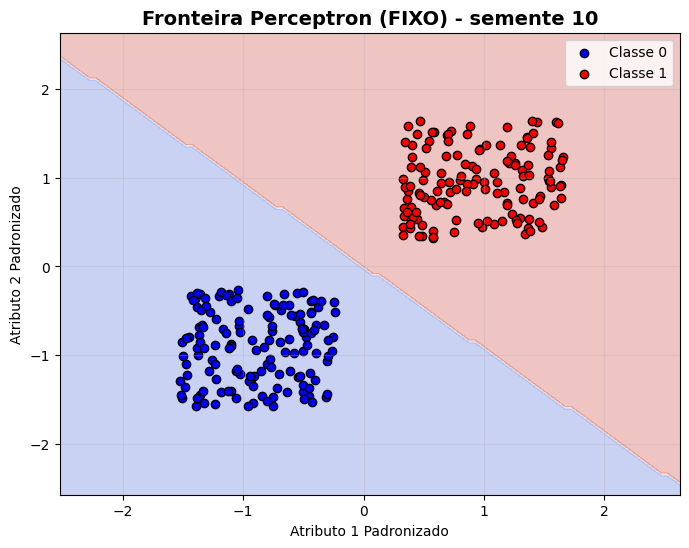

[Adaline - FIXO] Épocas: 100 | MSE final: 0.022979 | ACC treino: 1.00 | ACC teste: 1.00 | Pesos: [0.2335 0.2692] | Bias: 0.4893


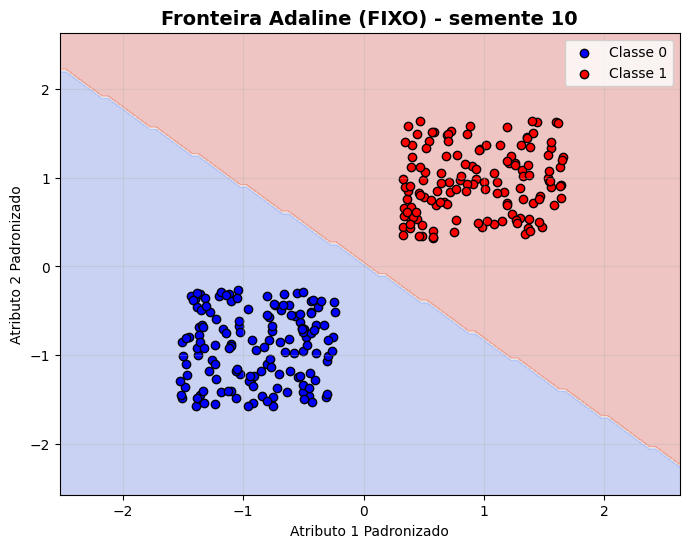

[Perceptron - EMBARALHADO] Épocas: 100 | ACC treino: 1.00 | ACC teste: 1.00 | Pesos: [0.0801 0.1238] | Bias: 0.0000


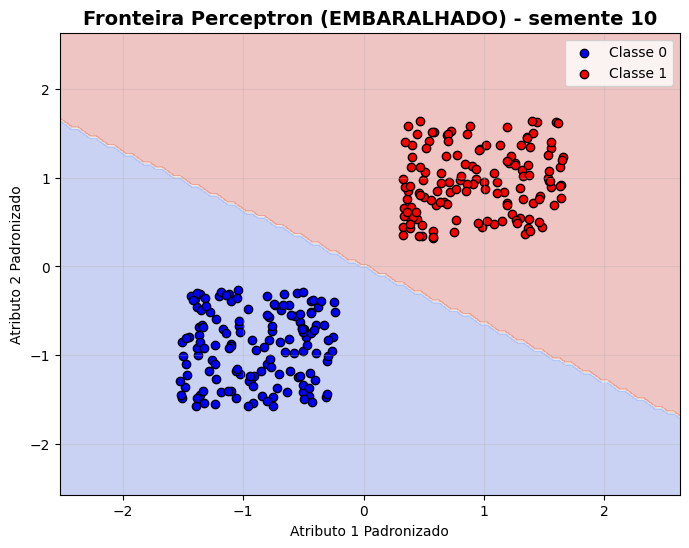

[Adaline - EMBARALHADO] Épocas: 100 | MSE final: 0.022946 | ACC treino: 1.00 | ACC teste: 1.00 | Pesos: [0.2343 0.2642] | Bias: 0.4915


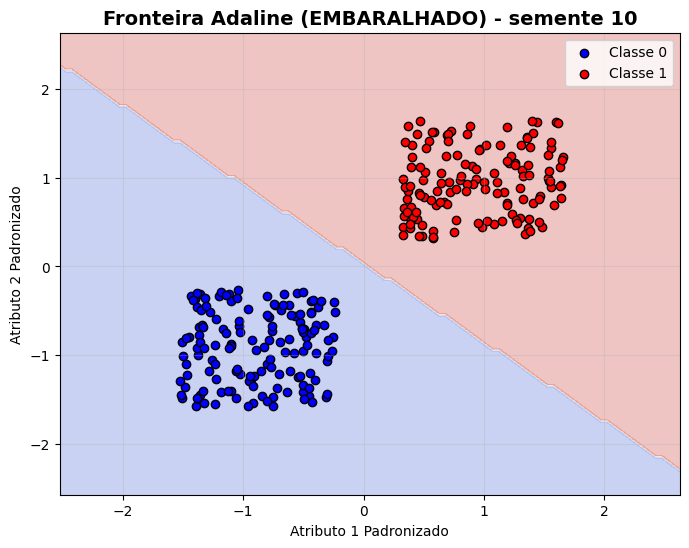


--- rodando para a semente 20 ---
[Perceptron - FIXO] Épocas: 100 | ACC treino: 1.00 | ACC teste: 1.00 | Pesos: [0.1687 0.1801] | Bias: 0.0000
[Adaline - FIXO] Épocas: 100 | MSE final: 0.022979 | ACC treino: 1.00 | ACC teste: 1.00 | Pesos: [0.2335 0.2692] | Bias: 0.4893
[Perceptron - EMBARALHADO] Épocas: 100 | ACC treino: 1.00 | ACC teste: 1.00 | Pesos: [0.1048 0.1081] | Bias: 0.0000
[Adaline - EMBARALHADO] Épocas: 100 | MSE final: 0.022984 | ACC treino: 1.00 | ACC teste: 1.00 | Pesos: [0.2347 0.2685] | Bias: 0.4886

--- rodando para a semente 30 ---
[Perceptron - FIXO] Épocas: 100 | ACC treino: 1.00 | ACC teste: 1.00 | Pesos: [0.1687 0.1801] | Bias: 0.0000
[Adaline - FIXO] Épocas: 100 | MSE final: 0.022979 | ACC treino: 1.00 | ACC teste: 1.00 | Pesos: [0.2335 0.2692] | Bias: 0.4893
[Perceptron - EMBARALHADO] Épocas: 100 | ACC treino: 1.00 | ACC teste: 1.00 | Pesos: [0.1896 0.1324] | Bias: 0.0000
[Adaline - EMBARALHADO] Épocas: 100 | MSE final: 0.023179 | ACC treino: 1.00 | ACC teste:

In [ ]:
for seed in sementes:

    print(f"\n--- rodando para a semente {seed} ---")

    for embaralhar_dados in [False, True]:

        modo = "EMBARALHADO" if embaralhar_dados else "FIXO"

        # perceptron
        w, b, erros_epoca, epocas_gastas = perceptron(
            x_train_pad, y_train,
            taxa_aprendizagem=0.1,
            max_epocas=100,
            embaralhar=embaralhar_dados,
            seed=seed
        )

        # faz as previsões
        y_pred_treino = previsoes_perceptron(x_train_pad, w, b)
        y_pred_teste = previsoes_perceptron(x_test_pad, w, b)

        # calcula as métricas
        acc_treino = calcular_acuracia(y_train, y_pred_treino)
        acc_teste = calcular_acuracia(y_test, y_pred_teste)

        # calcula a matriz de confusão
        matriz = calcular_matriz_confusao(y_test, y_pred_teste)

        # salva os resultados
        if embaralhar_dados:

            resultados_perceptron_embaralhado['epocas'].append(epocas_gastas)
            resultados_perceptron_embaralhado['acc_treino'].append(acc_treino)
            resultados_perceptron_embaralhado['acc_teste'].append(acc_teste)
            resultados_perceptron_embaralhado['pesos'].append(w.copy())
            resultados_perceptron_embaralhado['bias'].append(b)
            resultados_perceptron_embaralhado['erros_epoca'].append(erros_epoca.copy())
            resultados_perceptron_embaralhado['matrizes_confusao'].append(matriz)

        else:

            resultados_perceptron_fixo['epocas'].append(epocas_gastas)
            resultados_perceptron_fixo['acc_treino'].append(acc_treino)
            resultados_perceptron_fixo['acc_teste'].append(acc_teste)
            resultados_perceptron_fixo['pesos'].append(w.copy())
            resultados_perceptron_fixo['bias'].append(b)
            resultados_perceptron_fixo['erros_epoca'].append(erros_epoca.copy())
            resultados_perceptron_fixo['matrizes_confusao'].append(matriz)

        print(
            f"[Perceptron - {modo}] "
            f"Épocas: {epocas_gastas} | "
            f"ACC treino: {acc_treino:.2f} | "
            f"ACC teste: {acc_teste:.2f} | "
            f"Pesos: {w.round(4)} | "
            f"Bias: {b:.4f}"
        )

        # plota a fronteira da primeira semente
        if seed == 10:
            plotar_fronteira(
                x_train_pad, y_train, w, b,
                previsoes_perceptron,
                f"Fronteira Perceptron ({modo}) - semente {seed}"
            )

        # adaline
        w_a, b_a, mse_por_epoca = adaline(
            x_train_pad, y_train,
            taxa_aprendizagem=0.01,
            max_epocas=100,
            embaralhar=embaralhar_dados,
            seed=seed
        )

        # faz as previsões
        y_pred_treino_a = previsoes_adaline(x_train_pad, w_a, b_a)
        y_pred_teste_a = previsoes_adaline(x_test_pad, w_a, b_a)

        # calcula as métricas
        acc_treino_a = calcular_acuracia(y_train, y_pred_treino_a)
        acc_teste_a = calcular_acuracia(y_test, y_pred_teste_a)

        # calcula a matriz de confusão
        matriz_a = calcular_matriz_confusao(y_test, y_pred_teste_a)

        # salva os resultados
        if embaralhar_dados:

            resultados_adaline_embaralhado['epocas'].append(len(mse_por_epoca))
            resultados_adaline_embaralhado['acc_treino'].append(acc_treino_a)
            resultados_adaline_embaralhado['acc_teste'].append(acc_teste_a)
            resultados_adaline_embaralhado['mse_final'].append(mse_por_epoca[-1])
            resultados_adaline_embaralhado['pesos'].append(w_a.copy())
            resultados_adaline_embaralhado['bias'].append(b_a)
            resultados_adaline_embaralhado['mse_por_epoca'].append(mse_por_epoca.copy())
            resultados_adaline_embaralhado['matrizes_confusao'].append(matriz_a)

        else:

            resultados_adaline_fixo['epocas'].append(len(mse_por_epoca))
            resultados_adaline_fixo['acc_treino'].append(acc_treino_a)
            resultados_adaline_fixo['acc_teste'].append(acc_teste_a)
            resultados_adaline_fixo['mse_final'].append(mse_por_epoca[-1])
            resultados_adaline_fixo['pesos'].append(w_a.copy())
            resultados_adaline_fixo['bias'].append(b_a)
            resultados_adaline_fixo['mse_por_epoca'].append(mse_por_epoca.copy())
            resultados_adaline_fixo['matrizes_confusao'].append(matriz_a)

        print(
            f"[Adaline - {modo}] "
            f"Épocas: {len(mse_por_epoca)} | "
            f"MSE final: {mse_por_epoca[-1]:.6f} | "
            f"ACC treino: {acc_treino_a:.2f} | "
            f"ACC teste: {acc_teste_a:.2f} | "
            f"Pesos: {w_a.round(4)} | "
            f"Bias: {b_a:.4f}"
        )

        # plota a fronteira da primeira semente
        if seed == 10:
            plotar_fronteira(
                x_train_pad, y_train, w_a, b_a,
                previsoes_adaline,
                f"Fronteira Adaline ({modo}) - semente {seed}"
            )

### `Evolução do número de erros do Perceptron`

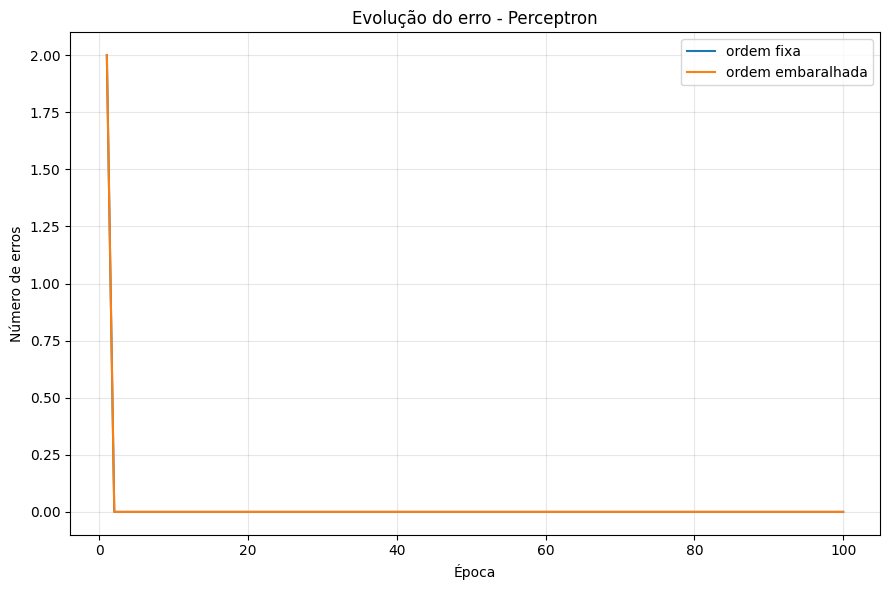

In [ ]:
erros_fixo = np.array(resultados_perceptron_fixo['erros_epoca'])
erros_embaralhado = np.array(resultados_perceptron_embaralhado['erros_epoca'])

media_erros_fixo = np.mean(erros_fixo, axis=0)
dp_erros_fixo = np.std(erros_fixo, axis=0)

media_erros_embaralhado = np.mean(erros_embaralhado, axis=0)
dp_erros_embaralhado = np.std(erros_embaralhado, axis=0)

epocas = np.arange(1, len(media_erros_fixo) + 1)

plt.figure(figsize=(9, 6))

plt.plot(epocas, media_erros_fixo, label='ordem fixa')

plt.fill_between(
    epocas,
    media_erros_fixo - dp_erros_fixo,
    media_erros_fixo + dp_erros_fixo,
    alpha=0.2
)

plt.plot(epocas, media_erros_embaralhado, label='ordem embaralhada')

plt.fill_between(
    epocas,
    media_erros_embaralhado - dp_erros_embaralhado,
    media_erros_embaralhado + dp_erros_embaralhado,
    alpha=0.2
)

plt.xlabel('Época')
plt.ylabel('Número de erros')
plt.title('Evolução do erro - Perceptron')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### `Evolução do MSE do Adaline`

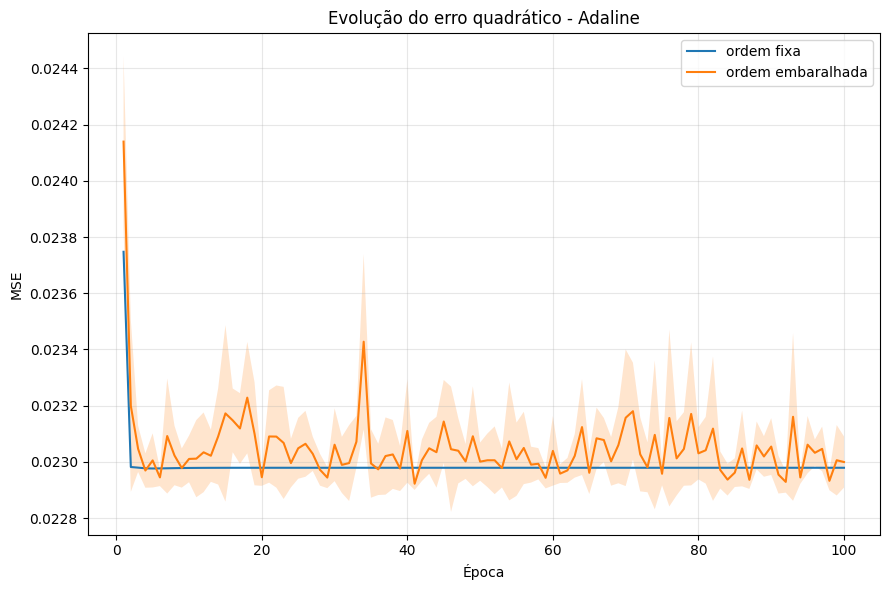

In [ ]:
mse_fixo = np.array(resultados_adaline_fixo['mse_por_epoca'])
mse_embaralhado = np.array(resultados_adaline_embaralhado['mse_por_epoca'])

media_mse_fixo = np.mean(mse_fixo, axis=0)
dp_mse_fixo = np.std(mse_fixo, axis=0)

media_mse_embaralhado = np.mean(mse_embaralhado, axis=0)
dp_mse_embaralhado = np.std(mse_embaralhado, axis=0)

epocas = np.arange(1, len(media_mse_fixo) + 1)

plt.figure(figsize=(9, 6))

plt.plot(epocas, media_mse_fixo, label='ordem fixa')

plt.fill_between(
    epocas,
    media_mse_fixo - dp_mse_fixo,
    media_mse_fixo + dp_mse_fixo,
    alpha=0.2
)

plt.plot(epocas, media_mse_embaralhado, label='ordem embaralhada')

plt.fill_between(
    epocas,
    media_mse_embaralhado - dp_mse_embaralhado,
    media_mse_embaralhado + dp_mse_embaralhado,
    alpha=0.2
)

plt.xlabel('Época')
plt.ylabel('MSE')
plt.title('Evolução do erro quadrático - Adaline')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### `Fronteiras do perceptron para as cinco sementes`

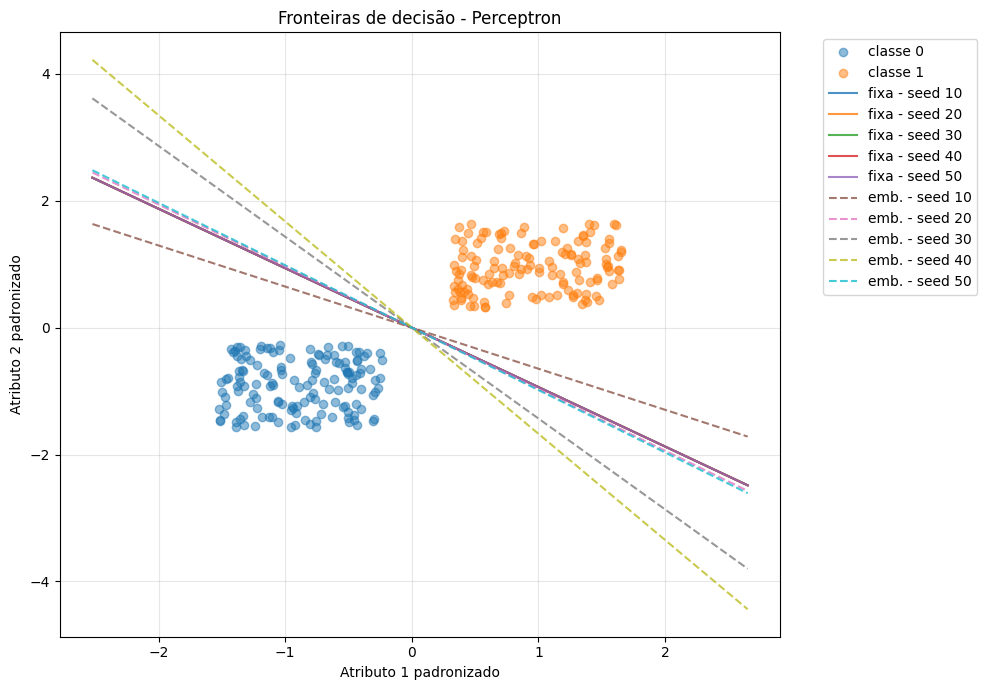

In [ ]:
plt.figure(figsize=(10, 7))

plt.scatter(
    x_train_pad[y_train == 0, 0],
    x_train_pad[y_train == 0, 1],
    alpha=0.5,
    label='classe 0')

plt.scatter(
    x_train_pad[y_train == 1, 0],
    x_train_pad[y_train == 1, 1],
    alpha=0.5,
    label='classe 1')

x_min = x_train_pad[:, 0].min() - 1
x_max = x_train_pad[:, 0].max() + 1
x_linha = np.linspace(x_min, x_max, 200)

# fronteiras da ordem fixa
for seed, pesos, bias in zip(
    sementes,
    resultados_perceptron_fixo['pesos'],
    resultados_perceptron_fixo['bias']
):

    if abs(pesos[1]) > 1e-12:

        y_linha = -(pesos[0] * x_linha + bias) / pesos[1]

        plt.plot(
            x_linha,
            y_linha,
            linestyle='-',
            alpha=0.8,
            label=f'fixa - seed {seed}')

# fronteiras da ordem embaralhada
for seed, pesos, bias in zip(
    sementes,
    resultados_perceptron_embaralhado['pesos'],
    resultados_perceptron_embaralhado['bias']
):

    if abs(pesos[1]) > 1e-12:

        y_linha = -(pesos[0] * x_linha + bias) / pesos[1]

        plt.plot(
            x_linha,
            y_linha,
            linestyle='--',
            alpha=0.8,
            label=f'emb. - seed {seed}')

plt.xlabel('Atributo 1 padronizado')
plt.ylabel('Atributo 2 padronizado')
plt.title('Fronteiras de decisão - Perceptron')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### `Fronteiras do adaline para as cinco sementes`

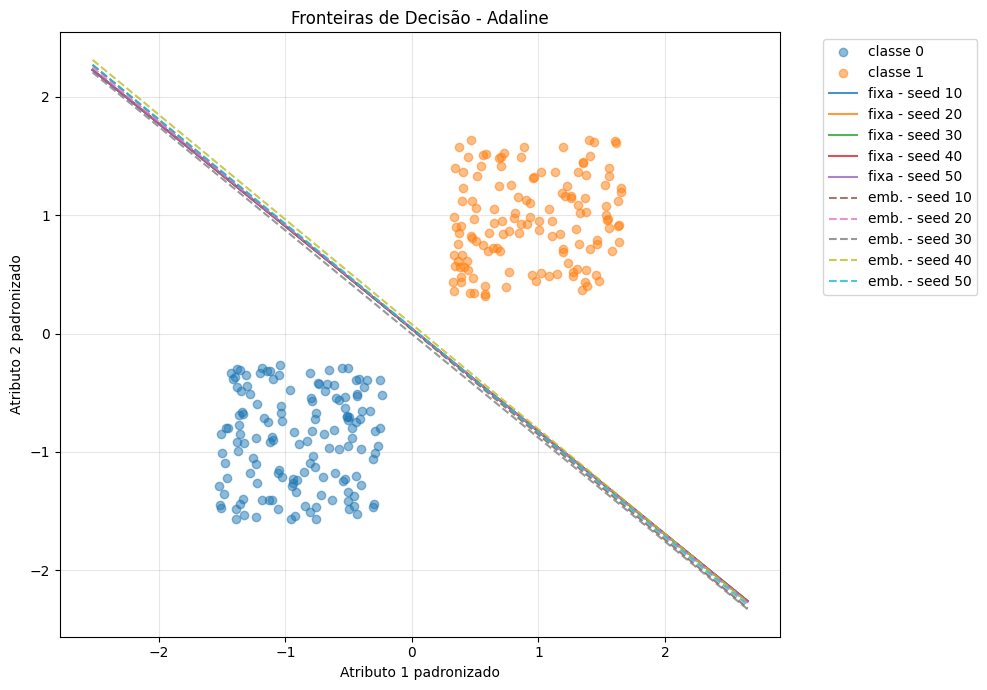

In [ ]:
plt.figure(figsize=(10, 7))

plt.scatter(
    x_train_pad[y_train == 0, 0],
    x_train_pad[y_train == 0, 1],
    alpha=0.5,
    label='classe 0')

plt.scatter(
    x_train_pad[y_train == 1, 0],
    x_train_pad[y_train == 1, 1],
    alpha=0.5,
    label='classe 1')

x_min = x_train_pad[:, 0].min() - 1
x_max = x_train_pad[:, 0].max() + 1
x_linha = np.linspace(x_min, x_max, 200)

# fronteiras da ordem fixa
for seed, pesos, bias in zip(
    sementes,
    resultados_adaline_fixo['pesos'],
    resultados_adaline_fixo['bias']
):

    if abs(pesos[1]) > 1e-12:

        y_linha = -(pesos[0] * x_linha + bias - 0.5) / pesos[1]

        plt.plot(
            x_linha,
            y_linha,
            linestyle='-',
            alpha=0.8,
            label=f'fixa - seed {seed}' )

# fronteiras da ordem embaralhada
for seed, pesos, bias in zip(
    sementes,
    resultados_adaline_embaralhado['pesos'],
    resultados_adaline_embaralhado['bias']
):

    if abs(pesos[1]) > 1e-12:

       y_linha = -(pesos[0] * x_linha + bias - 0.5) / pesos[1]

       plt.plot(
            x_linha,
            y_linha,
            linestyle='--',
            alpha=0.8,
            label=f'emb. - seed {seed}')

plt.xlabel('Atributo 1 padronizado')
plt.ylabel('Atributo 2 padronizado')
plt.title('Fronteiras de Decisão - Adaline')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### `Boxplot dos pesos do Perceptron`

/tmp/ipykernel_941/2525032690.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


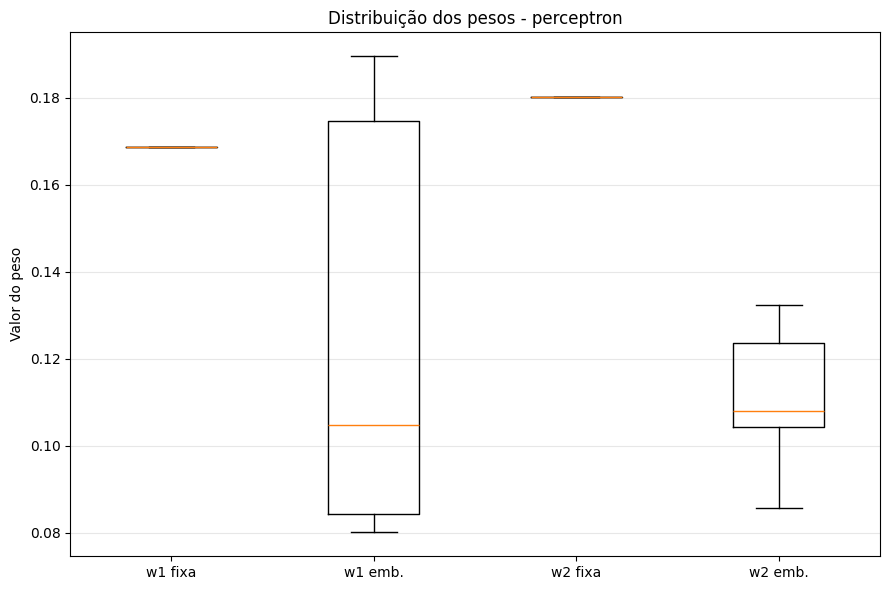

In [ ]:
pesos_p_fixo = np.array(resultados_perceptron_fixo['pesos'])
pesos_p_emb = np.array(resultados_perceptron_embaralhado['pesos'])

plt.figure(figsize=(9, 6))

plt.boxplot(
    [
        pesos_p_fixo[:, 0],
        pesos_p_emb[:, 0],
        pesos_p_fixo[:, 1],
        pesos_p_emb[:, 1]
    ],
    labels=['w1 fixa', 'w1 emb.', 'w2 fixa', 'w2 emb.']
)

plt.ylabel('Valor do peso')
plt.title('Distribuição dos pesos - perceptron')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### `Boxplot do bias e número de épocas do Perceptron`

/tmp/ipykernel_941/677830118.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


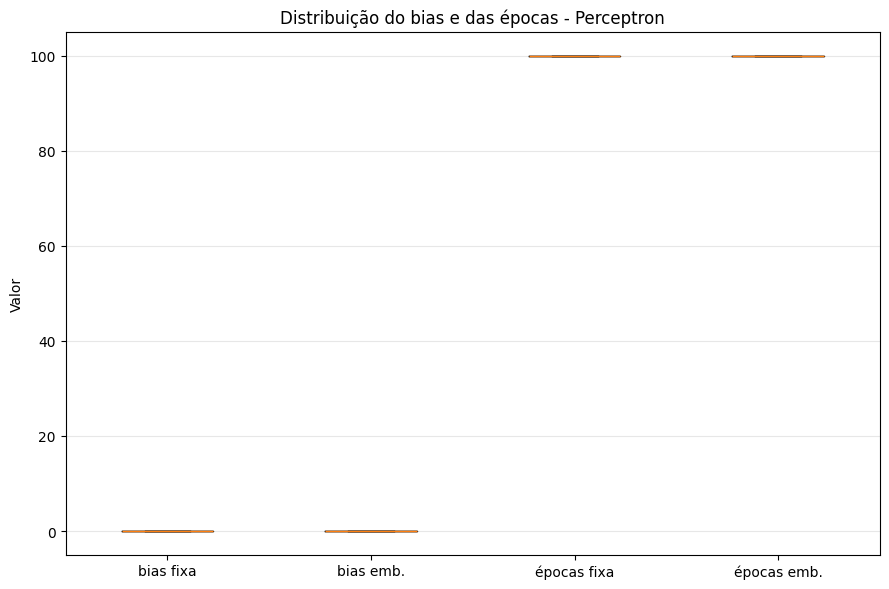

In [ ]:
plt.figure(figsize=(9, 6))

plt.boxplot(
    [
        resultados_perceptron_fixo['bias'],
        resultados_perceptron_embaralhado['bias'],
        resultados_perceptron_fixo['epocas'],
        resultados_perceptron_embaralhado['epocas']
    ],
    labels=[
        'bias fixa',
        'bias emb.',
        'épocas fixa',
        'épocas emb.'
    ]
)

plt.ylabel('Valor')
plt.title('Distribuição do bias e das épocas - Perceptron')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### `Boxplot dos pesos do Adaline`


/tmp/ipykernel_941/15848694.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


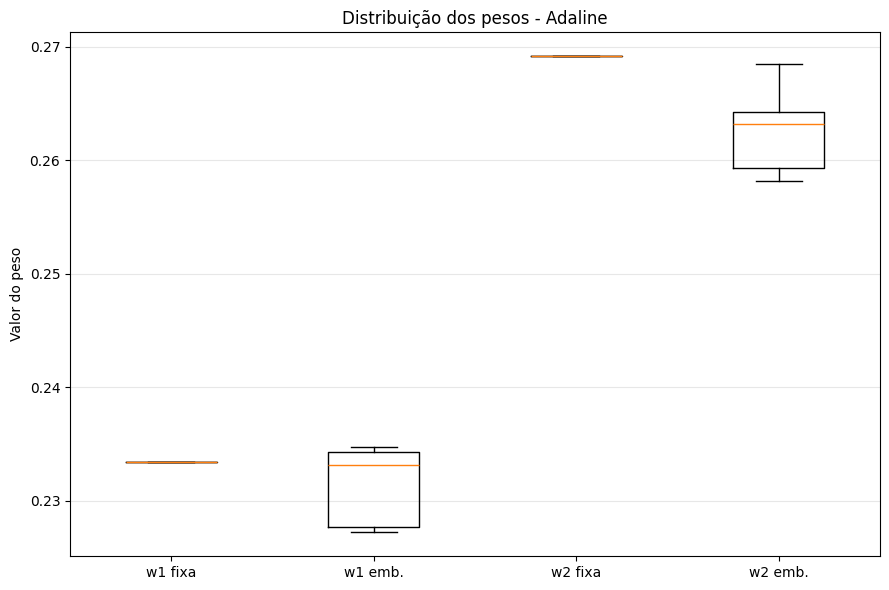

In [ ]:
pesos_a_fixo = np.array(
    resultados_adaline_fixo['pesos']
)

pesos_a_emb = np.array(
    resultados_adaline_embaralhado['pesos']
)

plt.figure(figsize=(9, 6))

plt.boxplot(
    [
        pesos_a_fixo[:, 0],
        pesos_a_emb[:, 0],
        pesos_a_fixo[:, 1],
        pesos_a_emb[:, 1]
    ],
    labels=[
        'w1 fixa',
        'w1 emb.',
        'w2 fixa',
        'w2 emb.'
    ]
)

plt.ylabel('Valor do peso')
plt.title('Distribuição dos pesos - Adaline')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### `Matriz de confusão`

In [ ]:
def plotar_matriz_confusao(matriz, titulo):

    plt.figure(figsize=(5, 4))

    plt.imshow(matriz, interpolation='nearest', cmap='RdPu')

    plt.title(titulo)
    plt.colorbar()

    plt.xticks([0, 1], ['classe 0', 'classe 1'])
    plt.yticks([0, 1], ['classe 0', 'classe 1'])

    plt.xlabel('classe prevista')
    plt.ylabel('classe real')

    for i in range(matriz.shape[0]):
        for j in range(matriz.shape[1]):

            plt.text(
                j, i,
                str(matriz[i, j]),
                ha='center',
                va='center'
            )

    plt.tight_layout()
    plt.show()

### `Matriz de confusão - Perceptron`

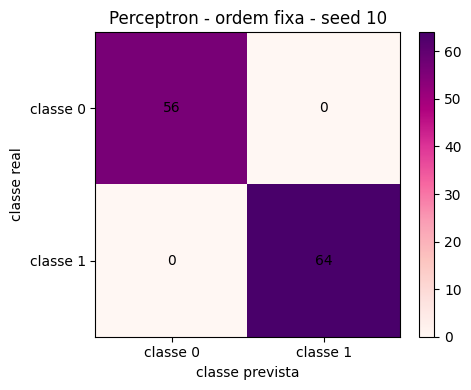

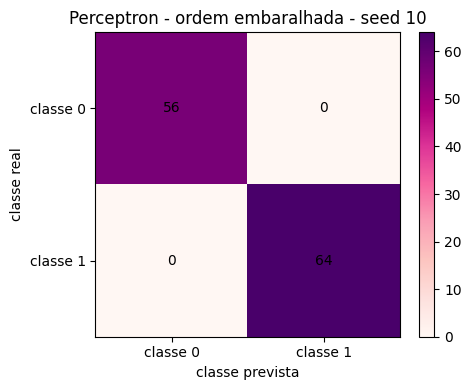

In [ ]:
plotar_matriz_confusao(
    resultados_perceptron_fixo['matrizes_confusao'][0],
    'Perceptron - ordem fixa - seed 10'
)

plotar_matriz_confusao(
    resultados_perceptron_embaralhado['matrizes_confusao'][0],
    'Perceptron - ordem embaralhada - seed 10'
)

### `Matriz de confusão - Adaline`

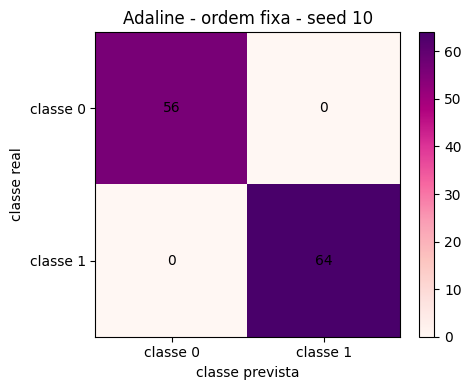

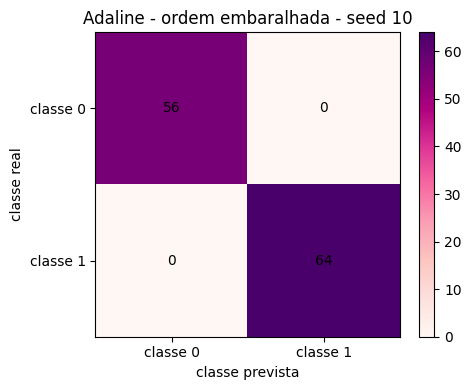

In [ ]:
plotar_matriz_confusao(
    resultados_adaline_fixo['matrizes_confusao'][0],
    'Adaline - ordem fixa - seed 10'
)

plotar_matriz_confusao(
    resultados_adaline_embaralhado['matrizes_confusao'][0],
    'Adaline - ordem embaralhada - seed 10'
)

### `Média e desvio padrão - Perceptron`

In [ ]:
pesos_perceptron_fixo = np.array(
    resultados_perceptron_fixo['pesos'])

pesos_perceptron_embaralhado = np.array(
    resultados_perceptron_embaralhado['pesos'])

bias_perceptron_fixo = np.array(
    resultados_perceptron_fixo['bias'])

bias_perceptron_embaralhado = np.array(
    resultados_perceptron_embaralhado['bias'])

print("Perceptron")
print("\nOrdem fixa:")

print( f"w1 = "
    f"{pesos_perceptron_fixo[:, 0].mean():.4f} ± "
    f"{pesos_perceptron_fixo[:, 0].std():.4f}")

print( f"w2 = "
    f"{pesos_perceptron_fixo[:, 1].mean():.4f} ± "
    f"{pesos_perceptron_fixo[:, 1].std():.4f}")

print( f"bias = "
    f"{bias_perceptron_fixo.mean():.4f} ± "
    f"{bias_perceptron_fixo.std():.4f}")

print( f"épocas = "
    f"{np.mean(resultados_perceptron_fixo['epocas']):.2f} ± "
    f"{np.std(resultados_perceptron_fixo['epocas']):.2f}")

print( f"acc treino = "
    f"{np.mean(resultados_perceptron_fixo['acc_treino']):.4f} ± "
    f"{np.std(resultados_perceptron_fixo['acc_treino']):.4f}")

print( f"acc teste = "
    f"{np.mean(resultados_perceptron_fixo['acc_teste']):.4f} ± "
    f"{np.std(resultados_perceptron_fixo['acc_teste']):.4f}")


print("\nOrdem embaralhada:")

print( f"w1 = "
    f"{pesos_perceptron_embaralhado[:, 0].mean():.4f} ± "
    f"{pesos_perceptron_embaralhado[:, 0].std():.4f}")

print( f"w2 = "
    f"{pesos_perceptron_embaralhado[:, 1].mean():.4f} ± "
    f"{pesos_perceptron_embaralhado[:, 1].std():.4f}")

print( f"bias = "
    f"{bias_perceptron_embaralhado.mean():.4f} ± "
    f"{bias_perceptron_embaralhado.std():.4f}")

print( f"épocas = "
    f"{np.mean(resultados_perceptron_embaralhado['epocas']):.2f} ± "
    f"{np.std(resultados_perceptron_embaralhado['epocas']):.2f}")

print( f"acc treino = "
    f"{np.mean(resultados_perceptron_embaralhado['acc_treino']):.4f} ± "
    f"{np.std(resultados_perceptron_embaralhado['acc_treino']):.4f}")

print(f"acc teste = "
    f"{np.mean(resultados_perceptron_embaralhado['acc_teste']):.4f} ± "
    f"{np.std(resultados_perceptron_embaralhado['acc_teste']):.4f}")

Perceptron

Ordem fixa:
w1 = 0.1687 ± 0.0000
w2 = 0.1801 ± 0.0000
bias = 0.0000 ± 0.0000
épocas = 100.00 ± 0.00
acc treino = 1.0000 ± 0.0000
acc teste = 1.0000 ± 0.0000

Ordem embaralhada:
w1 = 0.1267 ± 0.0463
w2 = 0.1109 ± 0.0162
bias = 0.0000 ± 0.0000
épocas = 100.00 ± 0.00
acc treino = 1.0000 ± 0.0000
acc teste = 1.0000 ± 0.0000


### `Média e desvio padrão - Adaline`

In [ ]:
pesos_adaline_fixo = np.array(
    resultados_adaline_fixo['pesos'])

pesos_adaline_embaralhado = np.array(
    resultados_adaline_embaralhado['pesos'])

bias_adaline_fixo = np.array(
    resultados_adaline_fixo['bias'])

bias_adaline_embaralhado = np.array(
    resultados_adaline_embaralhado['bias'])


print("Adaline")
print("\nOrdem fixa:")

print( f"w1 = "
    f"{pesos_adaline_fixo[:, 0].mean():.4f} ± "
    f"{pesos_adaline_fixo[:, 0].std():.4f}")

print( f"w2 = "
    f"{pesos_adaline_fixo[:, 1].mean():.4f} ± "
    f"{pesos_adaline_fixo[:, 1].std():.4f}")

print( f"bias = "
    f"{bias_adaline_fixo.mean():.4f} ± "
    f"{bias_adaline_fixo.std():.4f}")

print( f"épocas = "
    f"{np.mean(resultados_adaline_fixo['epocas']):.2f} ± "
    f"{np.std(resultados_adaline_fixo['epocas']):.2f}")

print( f"mse final = "
    f"{np.mean(resultados_adaline_fixo['mse_final']):.6f} ± "
    f"{np.std(resultados_adaline_fixo['mse_final']):.6f}")

print( f"acc treino = "
    f"{np.mean(resultados_adaline_fixo['acc_treino']):.4f} ± "
    f"{np.std(resultados_adaline_fixo['acc_treino']):.4f}")

print( f"acc teste = "
    f"{np.mean(resultados_adaline_fixo['acc_teste']):.4f} ± "
    f"{np.std(resultados_adaline_fixo['acc_teste']):.4f}")


print("\nOrdem embaralhada:")

print( f"w1 = "
    f"{pesos_adaline_embaralhado[:, 0].mean():.4f} ± "
    f"{pesos_adaline_embaralhado[:, 0].std():.4f}"
)

print( f"w2 = "
    f"{pesos_adaline_embaralhado[:, 1].mean():.4f} ± "
    f"{pesos_adaline_embaralhado[:, 1].std():.4f}")

print( f"bias = "
    f"{bias_adaline_embaralhado.mean():.4f} ± "
    f"{bias_adaline_embaralhado.std():.4f}")

print( f"épocas = "
    f"{np.mean(resultados_adaline_embaralhado['epocas']):.2f} ± "
    f"{np.std(resultados_adaline_embaralhado['epocas']):.2f}")

print( f"mse final = "
    f"{np.mean(resultados_adaline_embaralhado['mse_final']):.6f} ± "
    f"{np.std(resultados_adaline_embaralhado['mse_final']):.6f}")

print( f"acc treino = "
    f"{np.mean(resultados_adaline_embaralhado['acc_treino']):.4f} ± "
    f"{np.std(resultados_adaline_embaralhado['acc_treino']):.4f}")

print( f"acc teste = "
    f"{np.mean(resultados_adaline_embaralhado['acc_teste']):.4f} ± "
    f"{np.std(resultados_adaline_embaralhado['acc_teste']):.4f}")

Adaline

Ordem fixa:
w1 = 0.2335 ± 0.0000
w2 = 0.2692 ± 0.0000
bias = 0.4893 ± 0.0000
épocas = 100.00 ± 0.00
mse final = 0.022979 ± 0.000000
acc treino = 1.0000 ± 0.0000
acc teste = 1.0000 ± 0.0000

Ordem embaralhada:
w1 = 0.2314 ± 0.0033
w2 = 0.2627 ± 0.0037
bias = 0.4898 ± 0.0070
épocas = 100.00 ± 0.00
mse final = 0.022999 ± 0.000091
acc treino = 1.0000 ± 0.0000
acc teste = 1.0000 ± 0.0000


# `Discussão: relacionando os resultados às regras de aprendizagem`

### Objetivo do Experimento

* **Foco principal:** Investigar como a ordem de apresentação dos exemplos afeta o treinamento dos modelos.
* **Modelos testados:** Perceptron e Adaline.
* **Base de dados:** Conjunto linearmente separável e padronizado.
* **Metodologia:** Comparação de duas condições usando 5 sementes aleatórias:
1. Apresentação em **ordem fixa**.
2. **Embaralhamento** dos exemplos a cada época.


### Resultados: Perceptron

* **Condição de ordem fixa:** Produziu exatamente os mesmos pesos e *bias* em todas as 5 sementes (sequência de dados idêntica).
* **Condição de embaralhamento:** Gerou pesos e fronteiras de decisão diferentes entre as sementes.
* **Desempenho:** Acurácia de 100% nos treinos e testes, independente da semente.
* **A Regra de aprendizagem:**
* Os pesos são atualizados individualmente a cada erro de classificação.
* Logo, mudar a ordem muda o "caminho" de aprendizado.
* Como os dados são separáveis, o algoritmo apenas encontra *diferentes hiperplanos* que resolvem o mesmo problema sem perder a eficácia.


### Resultados: Adaline

* **Condição de ordem fixa:** Resultados idênticos em todas as execuções, assim como no Perceptron.
* **Condição de embaralhamento:** Apresentou apenas pequenas variações nos pesos, *bias* e no Erro Quadrático Médio (MSE). Foi muito **mais estável**.
* **A Regra de aprendizagem:**
* Utiliza a saída linear contínua para atualizar os pesos, focando na redução global do erro (MSE), e não apenas no erro binário de classificação.



# `Conclusão`

### Resumo dos achados

* A ordem de apresentação dos exemplos **influencia diretamente** o treinamento do Perceptron e do Adaline.
* Embora ambos os algoritmos tenham atingido **100% de acurácia** (treino e teste), eles chegaram a soluções matemáticas diferentes (variações nos pesos, *bias* e fronteira de decisão).

### O comportamento do Perceptron

* Foi o modelo **mais afetado** pela ordem dos dados.
* **Ordem fixa:** Mesmos resultados em todas as sementes.
* **Com embaralhamento:** Gerou diferentes pesos e fronteiras de decisão a cada execução, mas manteve intacta a capacidade de separar as classes corretamente.

### O comportamento do Adaline

* Mostrou-se muito **mais estável** frente à mudança na ordem dos exemplos.
* Apresentou apenas variações mínimas nos pesos, *bias* e no Erro Quadrático Médio (MSE).
* **Motivo:** Sua regra de aprendizagem baseia-se na saída linear e foca na minimização do erro quadrático.

### Resposta à pergunta principal

* **Os algoritmos NÃO chegam necessariamente à mesma solução.**
* Mesmo com o desempenho de classificação idêntico, ordens diferentes levam a caminhos e parâmetros finais diferentes (especialmente no Perceptron).
* **Conclusão Final:** A ordem dos dados é uma variável importante que molda o processo de aprendizagem e define os parâmetros finais dos modelos.